# 12 - Why did the models behave differently in the COVID fold?

Fold 2 of the rolling-origin evaluation (2020-02-10 to 2021-10-12). Data, proxies, models and settings are copied from notebook 10 (5 seeds, same fold boundaries); only fold 2 is retrained.

**Baseline note.** Fold 2 starts on 2020-02-10, so the "January 2020" baseline falls before it. The fold-2 models are therefore also asked to forecast from 2020-01-02 onward. Those January (and early-Feb) forecasts are *in-sample* for the models and are used only for the baseline and the left edge of the plots. All scoring uses fold-2 days only.

In [1]:
import sys, warnings, time
sys.path.append("..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import yfinance as yf
import tensorflow as tf
from tensorflow import keras  # type: ignore
from arch import arch_model

START = "2010-01-01"
N_SEEDS = 5
LOOK = 22
FOLD_START, FOLD_LEN = 0.6, 0.1           # fold 2 of notebook 10
REFIT_EVERY = 20
PRE_START = pd.Timestamp("2020-01-02")    # extra in-sample forecasts, baseline only
CRASH_START, CRASH_END = pd.Timestamp("2020-02-20"), pd.Timestamp("2020-04-30")

In [2]:
_cache = {}
def load_data(ticker):
    if ticker not in _cache:
        px = yf.download(ticker, start=START, auto_adjust=True, progress=False)
        if isinstance(px.columns, pd.MultiIndex):
            px.columns = px.columns.get_level_values(0)
        px = px[["Open", "High", "Low", "Close"]].dropna()
        r = (100 * np.log(px["Close"] / px["Close"].shift(1))).dropna()
        r.name = "log_return"
        _cache[ticker] = (r, px)
    return _cache[ticker]

def range_proxy(r, px):
    lnHL = np.log(px["High"] / px["Low"])
    lnCO = np.log(px["Close"] / px["Open"])
    lnON = np.log(px["Open"] / px["Close"].shift(1))
    gk = 1e4 * (0.5 * lnHL ** 2 - (2 * np.log(2) - 1) * lnCO ** 2)
    gk_on = (gk + 1e4 * lnON ** 2).loc[r.index]
    sq_ret = r ** 2
    roll_scale = (sq_ret.rolling(252, min_periods=126).sum()
                  / gk_on.rolling(252, min_periods=126).sum()).shift(1).bfill()
    return (roll_scale * gk_on).clip(lower=1e-6)

SPECS = {
    "GARCH(1,1)": dict(vol="GARCH", p=1, q=1),
    "EGARCH":     dict(vol="EGARCH", p=1, o=1, q=1),
    "GJR-GARCH":  dict(vol="GARCH", p=1, o=1, q=1),
}

def garch_forecasts(r, split, end, pre):
    """Estimate on r[:split] only; forecasts for r[pre:end] (pre < split gives in-sample baseline days)."""
    gf_all, test = {}, {}
    for name, spec in SPECS.items():
        res = arch_model(r, mean="Constant", dist="t", **spec).fit(last_obs=r.index[split - 1], disp="off")
        gf = res.forecast(horizon=1, start=r.index[0], reindex=False).variance["h.1"]
        gf_all[name] = gf
        test[name] = gf.shift(1).loc[r.index[pre:end]]
    test["Rolling 21d var"] = r.rolling(21).var().shift(1).loc[r.index[pre:end]]
    return gf_all, pd.DataFrame(test)

def har_design(x):
    return pd.DataFrame({"daily": x, "weekly": x.rolling(5).mean(), "monthly": x.rolling(22).mean()})

def rolling_har(series, split, end, pre, log=False):
    x = np.log(series) if log else series
    X = sm.add_constant(har_design(x))
    y_next = x.shift(-1)
    preds = []
    for s in range(split, end, REFIT_EVERY):
        e = min(s + REFIT_EVERY, end)
        Xt, yt = X.iloc[: s - 1], y_next.iloc[: s - 1]
        ok = Xt.notna().all(axis=1) & yt.notna()
        res = sm.OLS(yt[ok], Xt[ok]).fit()
        a = pre if s == split else s          # first block also forecasts the in-sample days
        p = res.predict(X.iloc[a - 1: e - 1])
        if log:
            p = np.exp(p + 0.5 * res.mse_resid)
        preds.append(pd.Series(p.values, index=series.index[a:e]))
    return pd.concat(preds)

In [3]:
def qlike_loss(y_true, y_pred):
    y_, base = y_true[:, 0:1], y_true[:, 1:2]
    out = tf.clip_by_value(y_pred, -4.0, 4.0)
    f = base * tf.exp(out)
    return tf.reduce_mean(tf.math.log(f) + y_ / f)

def build_model(n_feat, lr=3e-4):
    m = keras.Sequential([
        keras.layers.Input(shape=(LOOK, n_feat)),
        keras.layers.LSTM(16),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(1, kernel_initializer="zeros", bias_initializer="zeros"),
    ])
    m.compile(optimizer=keras.optimizers.Adam(lr), loss=qlike_loss)
    return m

def train_ensemble(s, n_seeds):
    """Returns (ensemble-mean forecast, per-seed clipped log-multipliers [seeds x days])."""
    preds, outs = [], []
    for seed in range(n_seeds):
        np.random.seed(seed); tf.random.set_seed(seed)
        m = build_model(s["X_tr"].shape[2])
        early = keras.callbacks.EarlyStopping(patience=15, restore_best_weights=True)
        m.fit(s["X_tr"], s["Y_tr"], validation_data=(s["X_val"], s["Y_val"]),
              epochs=200, batch_size=64, callbacks=[early], verbose=0)
        out = np.clip(m.predict(s["X_te"], verbose=0).ravel(), -4, 4)
        outs.append(out)
        preds.append(s["Y_te"][:, 1] * np.exp(out))
    return np.array(preds).mean(axis=0), np.array(outs)

def nn_forecasts(r, gjr_gf, split, end, n_seeds, pre_date):
    feat = pd.DataFrame({
        "ret": r, "sq_ret": r ** 2,
        "abs_mean_5d": r.abs().rolling(5).mean(),
        "rv_21d": r.rolling(21).std() * np.sqrt(252),
        "log_garch_var": np.log(gjr_gf),
    }).dropna()
    split_date = r.index[split]
    end_date = r.index[end] if end < len(r) else r.index[-1] + pd.Timedelta(days=1)

    tr = feat.index < split_date
    mu, sd = feat[tr].mean(), feat[tr].std()
    feat_s = ((feat - mu) / sd).clip(-5, 5)
    vals, idx = feat_s.values, feat_s.index
    rsq = (r ** 2).loc[idx].values
    gv = gjr_gf.loc[idx].values

    X, y, g, dates = [], [], [], []
    for t in range(LOOK, len(idx)):
        X.append(vals[t - LOOK:t]); y.append(rsq[t]); g.append(gv[t - 1]); dates.append(idx[t])
    X, y, g, dates = np.array(X), np.array(y), np.array(g), pd.DatetimeIndex(dates)

    train_mask = dates < split_date
    test_mask = (dates >= pre_date) & (dates < end_date)     # includes in-sample baseline days
    const_var = (r ** 2)[r.index < split_date].mean()

    def make_sets(X_, base):
        Y = np.column_stack([y, base])
        Xa, Ya = X_[train_mask], Y[train_mask]
        v = int(len(Xa) * 0.9)
        return dict(X_tr=Xa[:v], Y_tr=Ya[:v], X_val=Xa[v:], Y_val=Ya[v:],
                    X_te=X_[test_mask], Y_te=Y[test_mask])

    out = pd.DataFrame(index=dates[test_mask])
    out["Hybrid"], hyb_raw = train_ensemble(make_sets(X, g), n_seeds)
    out["LSTM"], _ = train_ensemble(make_sets(X[:, :, :4], np.full(len(y), const_var)), n_seeds)
    return out, pd.DataFrame(hyb_raw.T, index=dates[test_mask]), feat, mu, sd, split_date

In [4]:
r, px = load_data("^GSPC")
proxy_rb = range_proxy(r, px)
n = len(r)
split = int(n * FOLD_START)
end = min(int(n * (FOLD_START + FOLD_LEN)), n)       # identical expression to notebook 10
pre = r.index.searchsorted(PRE_START)
assert r.index[split] == pd.Timestamp("2020-02-10"), r.index[split]
print("Fold 2:", r.index[split].date(), "->", r.index[end - 1].date(), f"({end - split} days)")

t0 = time.time()
gf_all, fc = garch_forecasts(r, split, end, pre)
nn, hyb_raw, feat, mu, sd, split_date = nn_forecasts(r, gf_all["GJR-GARCH"], split, end, N_SEEDS, PRE_START)
floor = 0.01 * proxy_rb.iloc[:split].mean()
har = rolling_har(proxy_rb, split, end, pre).clip(lower=floor).rename("HAR")
loghar = rolling_har(proxy_rb, split, end, pre, log=True).rename("log-HAR")
fc_all = fc.join(nn, how="inner").join(har, how="inner").join(loghar, how="inner").dropna().clip(lower=1e-8)
fc = fc_all.loc[fc_all.index >= split_date]           # the real fold-2 evaluation set
print(f"retrained in {time.time() - t0:.0f}s; fold days: {len(fc)}; incl. in-sample baseline days: {len(fc_all)}")

MODELS = list(fc.columns)
PROXIES = {"Squared returns": r ** 2, "Range-based": proxy_rb}
loss = {pn: fc.apply(lambda f: np.log(f) + p.loc[fc.index] / f) for pn, p in PROXIES.items()}
print("\nSanity check - fold-2 QLIKE (compare with notebook 10's fold 2 row):")
display(pd.DataFrame({pn: L.mean() for pn, L in loss.items()}).round(4))

phase = pd.Series("recovery", index=fc.index)
phase[fc.index < CRASH_START] = "pre-crash"
phase[(fc.index >= CRASH_START) & (fc.index <= CRASH_END)] = "crash"
PHASES = ["pre-crash", "crash", "recovery"]
print(phase.value_counts()[PHASES].to_dict())

Fold 2: 2020-02-10 -> 2021-10-12 (423 days)


retrained in 321s; fold days: 423; incl. in-sample baseline days: 449

Sanity check - fold-2 QLIKE (compare with notebook 10's fold 2 row):


,Squared returns,Range-based
"GARCH(1,1)",1.2750,1.3731
EGARCH,1.6732,1.6501
GJR-GARCH,1.4386,1.4952
Rolling 21d var,1.4540,1.5169
Hybrid,1.4445,1.5230
LSTM,1.6746,1.8514
HAR,1.2323,1.3134
log-HAR,1.2295,1.3240


{'pre-crash': 7, 'crash': 50, 'recovery': 366}


## 1. Forecast paths, Feb 1 - Jun 30 2020 (log scale)
Shaded area = before fold 2 starts (in-sample forecasts).

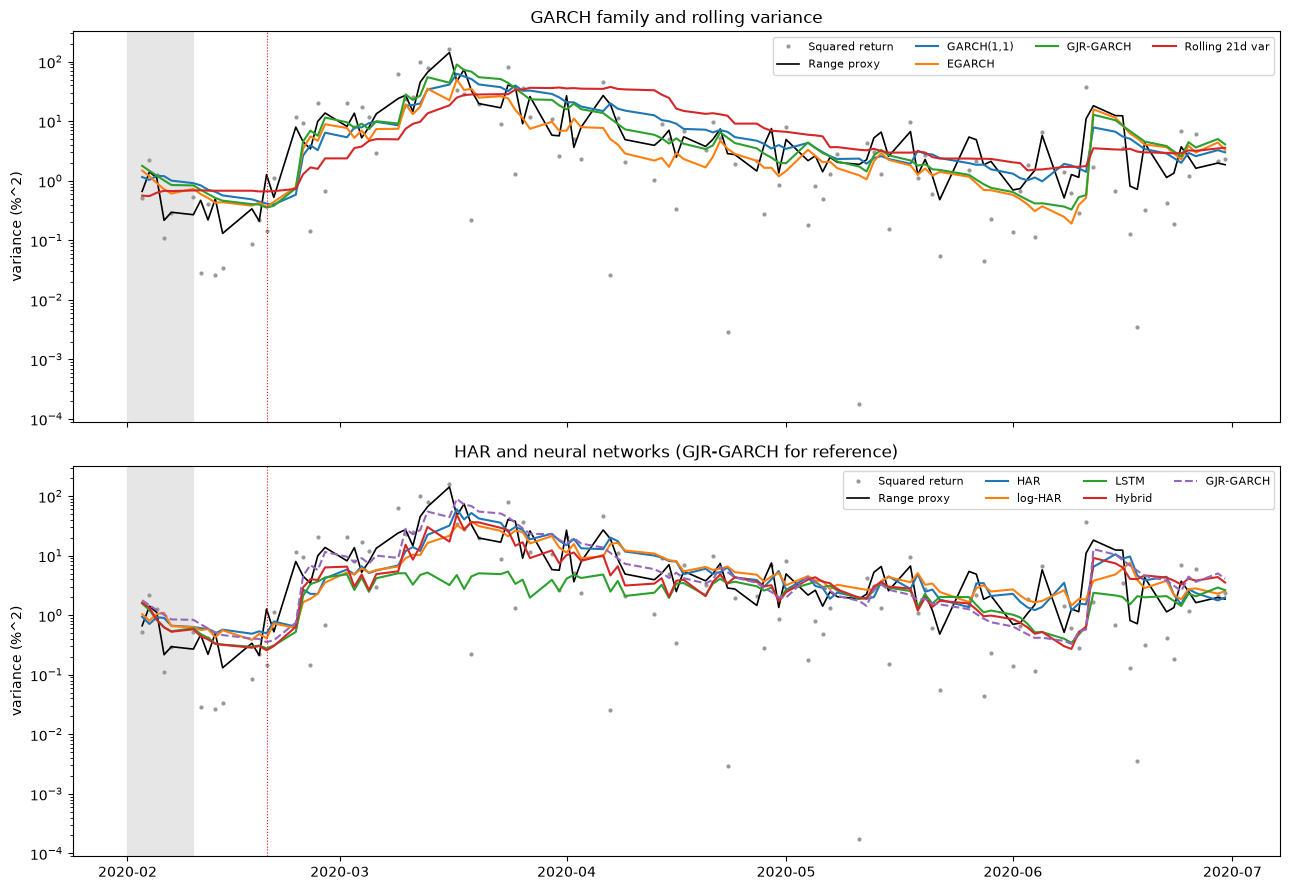

In [5]:
w = slice("2020-02-01", "2020-06-30")
groups = {"GARCH family and rolling variance": ["GARCH(1,1)", "EGARCH", "GJR-GARCH", "Rolling 21d var"],
          "HAR and neural networks (GJR-GARCH for reference)": ["HAR", "log-HAR", "LSTM", "Hybrid", "GJR-GARCH"]}
fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)
for ax, (title, ms) in zip(axes, groups.items()):
    ax.plot(r.loc[w].index, (r ** 2).loc[w], ".", color="0.6", ms=4, label="Squared return")
    ax.plot(proxy_rb.loc[w].index, proxy_rb.loc[w], "-", color="black", lw=1.2, label="Range proxy")
    for m in ms:
        ax.plot(fc_all.loc[w].index, fc_all.loc[w, m], lw=1.5, label=m, ls="--" if m == "GJR-GARCH" and len(ms) == 5 else "-")
    ax.axvspan(pd.Timestamp("2020-02-01"), split_date, color="0.9", zorder=0)
    ax.axvline(CRASH_START, color="red", lw=0.8, ls=":")
    ax.set_yscale("log"); ax.set_ylabel("variance (%^2)"); ax.set_title(title); ax.legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.show()

## 2. Reaction speed
Baseline = mean forecast in Jan 2020 (in-sample for the models). Days are trading days counted from Feb 20 (= day 0), searched through Jun 30. Peak = within the crash phase (Feb 20 - Apr 30).

In [6]:
base = fc_all.loc["2020-01-01":"2020-01-31"].mean()
look = fc_all.loc["2020-02-20":"2020-06-30"]
cw = fc_all.loc[CRASH_START:CRASH_END]
def first_cross(s, level):
    hit = np.flatnonzero(s.values >= level)
    return int(hit[0]) if len(hit) else np.nan
rows = {}
for m in MODELS:
    rows[m] = {"Jan-2020 level": base[m],
               "days to 2x": first_cross(look[m], 2 * base[m]),
               "days to 5x": first_cross(look[m], 5 * base[m]),
               "peak forecast": cw[m].max(), "peak date": cw[m].idxmax().date(),
               "peak / baseline": cw[m].max() / base[m]}
react = pd.DataFrame(rows).T
display(react.round(3))
ref = {}
for pn, p in PROXIES.items():
    b = p.loc["2020-01-01":"2020-01-31"].mean(); pk = p.loc[CRASH_START:CRASH_END]
    ref[pn] = {"Jan-2020 mean": b, "peak": pk.max(), "peak date": pk.idxmax().date(), "peak / Jan mean": pk.max() / b}
print("Proxy peaks for comparison:")
display(pd.DataFrame(ref).T.round(3))

,Jan-2020 level,days to 2x,days to 5x,peak forecast,peak date,peak / baseline
"GARCH(1,1)",0.424596,3,3,62.733661,2020-03-17,147.749216
EGARCH,0.377722,2,3,50.611889,2020-03-17,133.992396
GJR-GARCH,0.444315,3,3,89.9451,2020-03-17,202.435223
Rolling 21d var,0.237911,0,3,37.765921,2020-04-07,158.739394
Hybrid,0.458202,3,3,49.061391,2020-03-17,107.073656
LSTM,0.371637,3,3,5.414255,2020-03-24,14.568655
HAR,0.517457,3,3,60.182679,2020-03-17,116.304732
log-HAR,0.439713,3,5,37.278429,2020-03-19,84.779006


Proxy peaks for comparison:


,Jan-2020 mean,peak,peak date,peak / Jan mean
Squared returns,0.536535,162.950835,2020-03-16,303.709764
Range-based,0.588273,142.924714,2020-03-16,242.956401


## 3. Where the losses come from
Phases: pre-crash (to Feb 19), crash (Feb 20 - Apr 30), recovery (May 1 onward).

QLIKE by phase - Squared returns proxy


,pre-crash,crash,recovery
"GARCH(1,1)",-0.1641,4.0154,0.9282
EGARCH,-0.3587,3.9429,1.4020
GJR-GARCH,-0.2899,3.7721,1.1529
Rolling 21d var,-0.1018,4.6928,1.0413
Hybrid,-0.5343,4.1004,1.1195
LSTM,-0.5154,6.3036,1.0841
HAR,-0.2560,4.1042,0.8685
log-HAR,-0.3250,4.2573,0.8456


QLIKE by phase - Range-based proxy


,pre-crash,crash,recovery
"GARCH(1,1)",0.0291,3.7100,1.0796
EGARCH,-0.0777,3.8191,1.3869
GJR-GARCH,-0.0454,3.5943,1.2379
Rolling 21d var,0.0644,4.2026,1.1778
Hybrid,-0.1568,3.9223,1.2273
LSTM,-0.1502,6.3849,1.2703
HAR,-0.0257,3.7857,1.0012
log-HAR,-0.0468,3.9136,0.9964


Days per phase: {'pre-crash': 7, 'crash': 50, 'recovery': 366}
Contribution to fold-average QLIKE gap vs GJR-GARCH - Squared returns (negative = better than GJR)


,pre-crash,crash,recovery,total
"GARCH(1,1)",0.0021,0.0287,-0.1944,-0.1636
EGARCH,-0.0011,0.0202,0.2155,0.2346
Rolling 21d var,0.0031,0.1088,-0.0965,0.0154
Hybrid,-0.0040,0.0388,-0.0289,0.0058
LSTM,-0.0037,0.2992,-0.0595,0.2360
HAR,0.0006,0.0393,-0.2461,-0.2063
log-HAR,-0.0006,0.0573,-0.2659,-0.2091


Contribution to fold-average QLIKE gap vs GJR-GARCH - Range-based (negative = better than GJR)


,pre-crash,crash,recovery,total
"GARCH(1,1)",0.0012,0.0137,-0.1370,-0.1221
EGARCH,-0.0005,0.0266,0.1289,0.1549
Rolling 21d var,0.0018,0.0719,-0.0520,0.0217
Hybrid,-0.0018,0.0388,-0.0092,0.0278
LSTM,-0.0017,0.3299,0.0280,0.3561
HAR,0.0003,0.0226,-0.2048,-0.1819
log-HAR,-0.0000,0.0377,-0.2090,-0.1712


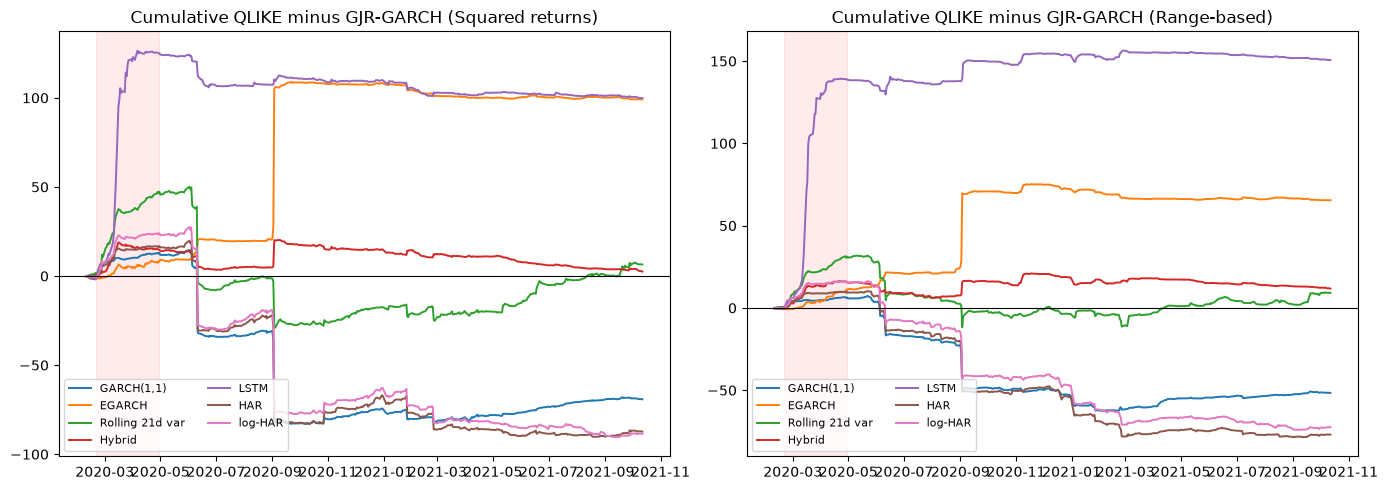

In [7]:
by_phase = {}
for pn, L in loss.items():
    t = L.groupby(phase).mean().T[PHASES]
    by_phase[pn] = t
    print(f"QLIKE by phase - {pn} proxy")
    display(t.round(4))
print("Days per phase:", phase.value_counts()[PHASES].to_dict())

# Contribution to the fold-level gap: sum of (model - GJR) loss per phase, divided by fold length
for pn, L in loss.items():
    d = L.sub(L["GJR-GARCH"], axis=0).groupby(phase).sum().T[PHASES] / len(L)
    d["total"] = d.sum(axis=1)
    print(f"Contribution to fold-average QLIKE gap vs GJR-GARCH - {pn} (negative = better than GJR)")
    display(d.drop("GJR-GARCH").round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
for ax, (pn, L) in zip(axes, loss.items()):
    cum = L.sub(L["GJR-GARCH"], axis=0).cumsum()
    for m in MODELS:
        if m != "GJR-GARCH":
            ax.plot(cum.index, cum[m], label=m, lw=1.4)
    ax.axhline(0, color="black", lw=0.8); ax.axvspan(CRASH_START, CRASH_END, color="red", alpha=0.08)
    ax.set_title(f"Cumulative QLIKE minus GJR-GARCH ({pn})"); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

## 4. Under- vs over-prediction
Mean of log(proxy / forecast); positive = the model under-predicted. A perfectly calibrated forecast gives about -1.27 for squared returns under normal errors (E[log chi-square(1)]) and a value nearer 0 for the less noisy range proxy, so compare models with each other and across phases rather than against zero.

In [8]:
for pn, p in PROXIES.items():
    lr_ = np.log(p.loc[fc.index].values[:, None] / fc.values)
    t = pd.DataFrame(lr_, index=fc.index, columns=MODELS).groupby(phase).mean().T[PHASES]
    print(f"Mean log(proxy / forecast) - {pn}")
    display(t.round(3))

Mean log(proxy / forecast) - Squared returns


,pre-crash,crash,recovery
"GARCH(1,1)",-1.847,-0.789,-1.357
EGARCH,-1.584,-0.160,-1.203
GJR-GARCH,-1.681,-0.703,-1.227
Rolling 21d var,-1.910,-0.825,-1.334
Hybrid,-1.294,-0.198,-1.137
LSTM,-1.331,0.475,-1.125
HAR,-1.711,-0.597,-1.474
log-HAR,-1.624,-0.481,-1.415


Mean log(proxy / forecast) - Range-based


,pre-crash,crash,recovery
"GARCH(1,1)",-0.832,-0.135,-0.277
EGARCH,-0.569,0.494,-0.123
GJR-GARCH,-0.666,-0.048,-0.147
Rolling 21d var,-0.895,-0.170,-0.255
Hybrid,-0.280,0.456,-0.057
LSTM,-0.317,1.129,-0.045
HAR,-0.696,0.058,-0.394
log-HAR,-0.609,0.173,-0.336


## 5. Hybrid internals
The network outputs a log-multiplier (clipped to +/-4) on the GJR-GARCH forecast. Ensemble multiplier = log(Hybrid forecast / GJR forecast); per-seed values are the raw clipped network outputs.

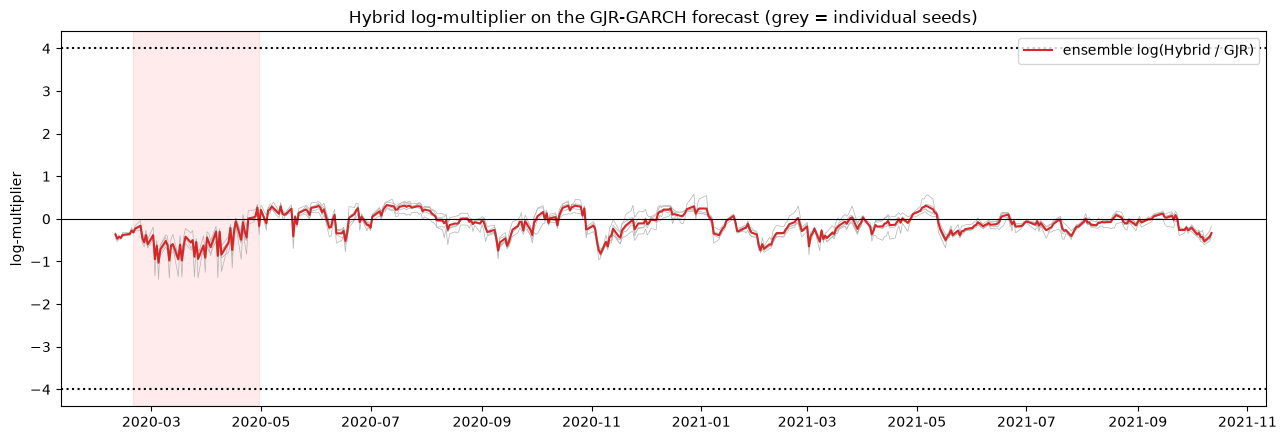

,mean ensemble log-mult,share of days ensemble > 0,share of seed-days at +4 clip,share of seed-days at -4 clip
pre-crash,-0.386,0.000,0.0,0.0
crash,-0.504,0.080,0.0,0.0
recovery,-0.090,0.339,0.0,0.0


Whole fold: share of seed-days at the +/-4 clip = 0.0% (+4: 0.0%, -4: 0.0%)
During the crash the network LOWERED the GJR forecast on average (mean log-multiplier -0.50, i.e. x0.60); raised on 8% of crash days.


In [9]:
ens_lm = np.log(fc["Hybrid"] / fc["GJR-GARCH"])
seed_lm = hyb_raw.loc[fc.index]
at_clip = (seed_lm.abs() >= 4 - 1e-6)

fig, ax = plt.subplots(figsize=(13, 4.5))
for c in seed_lm.columns:
    ax.plot(seed_lm.index, seed_lm[c], lw=0.5, color="0.7")
ax.plot(ens_lm.index, ens_lm, color="C3", lw=1.5, label="ensemble log(Hybrid / GJR)")
ax.axhline(0, color="black", lw=0.8); ax.axhline(4, ls=":", color="k"); ax.axhline(-4, ls=":", color="k")
ax.axvspan(CRASH_START, CRASH_END, color="red", alpha=0.08)
ax.set_ylabel("log-multiplier"); ax.set_title("Hybrid log-multiplier on the GJR-GARCH forecast (grey = individual seeds)")
ax.legend(); plt.tight_layout(); plt.show()

summ = pd.DataFrame({
    "mean ensemble log-mult": ens_lm.groupby(phase).mean(),
    "share of days ensemble > 0": (ens_lm > 0).groupby(phase).mean(),
    "share of seed-days at +4 clip": (seed_lm >= 4 - 1e-6).mean(axis=1).groupby(phase).mean(),
    "share of seed-days at -4 clip": (seed_lm <= -4 + 1e-6).mean(axis=1).groupby(phase).mean(),
}).loc[PHASES]
display(summ.round(3))
print(f"Whole fold: share of seed-days at the +/-4 clip = {at_clip.values.mean():.1%}"
      f" (+4: {(seed_lm >= 4 - 1e-6).values.mean():.1%}, -4: {(seed_lm <= -4 + 1e-6).values.mean():.1%})")
c = ens_lm[phase == "crash"]
print(f"During the crash the network {'RAISED' if c.mean() > 0 else 'LOWERED'} the GJR forecast on average "
      f"(mean log-multiplier {c.mean():+.2f}, i.e. x{np.exp(c.mean()):.2f}); raised on {(c > 0).mean():.0%} of crash days.")

## 6. Input extrapolation
Features are z-scored with training-period mean/std (then clipped to +/-5 before entering the network). Below, z-scores are computed *before* the clip. Crash days = feature dates Feb 20 - Apr 30 2020. The LSTM uses the first four features; the hybrid also uses log_garch_var.

In [10]:
z = (feat - mu) / sd
ztr = z[feat.index < split_date]
zc = z.loc[CRASH_START:CRASH_END]
nets = {"ret": "LSTM + Hybrid", "sq_ret": "LSTM + Hybrid", "abs_mean_5d": "LSTM + Hybrid",
        "rv_21d": "LSTM + Hybrid", "log_garch_var": "Hybrid only"}
rows = {}
for f_ in z.columns:
    beyond_hi = zc[f_] > ztr[f_].max()
    beyond_lo = zc[f_] < ztr[f_].min()
    rows[f_] = {"used by": nets[f_],
                "train max (z)": ztr[f_].max(), "train min (z)": ztr[f_].min(),
                "crash max (z)": zc[f_].max(), "crash min (z)": zc[f_].min(),
                "crash days > train max": int(beyond_hi.sum()), "crash days < train min": int(beyond_lo.sum()),
                "max excess above train max (SD)": max(zc[f_].max() - ztr[f_].max(), 0),
                "crash days beyond +/-5 (clipped)": int((zc[f_].abs() > 5).sum())}
ext = pd.DataFrame(rows).T
display(ext.round(2))
nc = len(zc)
for name, cols in {"LSTM (4 features)": list(z.columns[:4]), "Hybrid (5 features)": list(z.columns)}.items():
    any_beyond = (zc[cols] > ztr[cols].max()).any(axis=1)
    print(f"{name}: {int(any_beyond.sum())} of {nc} crash days have at least one feature above its training maximum")

,used by,train max (z),train min (z),crash max (z),crash min (z),crash days > train max,crash days < train min,max excess above train max (SD),crash days beyond +/-5 (clipped)
ret,LSTM + Hybrid,5.161212,-7.467255,9.603075,-13.782893,5,3,4.441862,11
sq_ret,LSTM + Hybrid,21.108815,-0.391207,73.284028,-0.389891,5,0,52.175213,16
abs_mean_5d,LSTM + Hybrid,8.39196,-1.361234,18.562175,-0.798038,13,0,10.170215,25
rv_21d,LSTM + Hybrid,5.292015,-1.423812,12.329831,-0.030648,30,0,7.037816,33
log_garch_var,Hybrid only,4.100226,-1.447897,5.661855,-0.541625,15,0,1.56163,6


LSTM (4 features): 32 of 50 crash days have at least one feature above its training maximum
Hybrid (5 features): 32 of 50 crash days have at least one feature above its training maximum


## Summary: what explains the differences in the COVID fold

*All numbers are from this run. The neural networks are not bit-reproducible, so their fold-2 QLIKE differs slightly from notebook 10 (Hybrid 1.445 vs 1.493 on squared returns, LSTM 1.675 vs 1.701; the Hybrid's squared-return rank moves from 6th to 5th). GARCH and HAR results match notebook 10 exactly.*

1. **Nobody was slow to react.** Every model's forecast passed 2x and 5x its January level within 3 trading days of Feb 20. The differences are in *how high* the forecasts went, not how quickly they started rising. GJR-GARCH peaked at 90 (proxy peaks: 143 range-based, 163 squared return), the Hybrid at 49, and the LSTM at only 5.4.
2. **The LSTM lost the crash.** It contributes +0.30 (squared returns) and +0.33 (range proxy) to its fold-average QLIKE gap vs GJR-GARCH during the 50 crash days alone, and it under-predicted there (mean log(proxy/forecast) +0.48 and +1.13, positive = under-predicted). Its inputs were far outside the training range: 32 of 50 crash days had a feature above its training maximum, with squared return up to 73 SD (training max 21 SD). Because features are clipped at +/-5 SD before entering the network, it could not tell a 5 SD day from a 70 SD day.
3. **The Hybrid's problem was not clipping but direction.** No seed ever hit the +/-4 clip. During the crash the network *lowered* the GJR-GARCH forecast on average (mean log-multiplier -0.50, about x0.60; it raised it on only 8% of crash days). It shaved the peak off (49 vs 90) and left the Hybrid slightly behind GJR-GARCH in the crash under both proxies, with no offsetting gain afterwards (+0.006 / +0.028 overall).
4. **HAR and GARCH(1,1) won the fold in the recovery phase, not the crash.** In the crash HAR/log-HAR were slightly worse than GJR-GARCH (+0.02 to +0.06). Their advantage (-0.20 to -0.27) comes from the 366 recovery days, where GJR-GARCH and EGARCH stayed too high for too long (EGARCH is worst there, +0.13 to +0.22 vs GJR-GARCH) while the HAR family and GARCH(1,1) scored better (the phase tables show the loss gap, not the mechanism). The range proxy makes the HAR edge look smaller in the recovery phase (-0.20 vs -0.25) but significant in the fold-level DM test, because the proxy is less noisy.
5. **Caveat.** The crash phase is only 50 of 423 days but carries very large per-day losses (QLIKE about 3.6-6.4 vs about 1 in recovery), so a handful of days drive the ranking and one fold with five seeds is a thin basis for conclusions about the networks. Positive log(proxy/forecast) means under-prediction; for squared returns even a perfect forecast averages about -1.27, so compare models, not the sign.
